# Analisando o engajamento do Instagram

**o que queremos responder?**
- Qual tipo de conteudo **mais engaja** no instagram da minha empresa?

- Temos a base de dados do instagram **desde que o usuario começou a postar na marca até o dia 27/março**

- Ele também dá alguns direcionamentos:
  - Podem ignorar a coluna visualizações, queremos entender apenas curtidas, comentários e interações
  - Tags vazias é que realmente não possuem tag (favor tratar como vazio)

## Vamos importar e visualizar a nossa base

In [ ]:
# Importando o pandas
import pandas as pd

In [ ]:
# Importar a base em excel
# - Base: 08. Analisando o engajamento no instagram.xlsx

data = pd.read_excel('08. Analisando o engajamento no Instagram.xlsx')

In [ ]:
# Visualizando as 5 primeiras linhas
data.head()

,Tipo,Data,Curtidas,Comentários,Visualizações,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,NaN,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,NaN,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,NaN,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,82878.0,Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,NaN,Produtos,S,N,NaN,4437


### Como ele pediu para não considerar a coluna visualizações, vamos retirar essa coluna da base

**O .drop() permite apagar uma coluna ou linha da base:**
base.drop(nome_coluna, axis=1)

- O axis = 1 se refere a coluna, enquanto axis = 0 se refere a linha
- Devemos passar o nome da coluna que queremos apagar da base
- Em caso de mais de 1 coluna, passamos a lista entre colchetes

In [ ]:
# Apagando a coluna "Visualizações"

data = data.drop("Visualizações", axis=1)

In [ ]:
# Visualizando novamente as 5 primeiras linhas
data.head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,Produtos,S,N,NaN,4437


In [ ]:
# Visualizando as 5 ultimas linhas
data.tail()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
47,IGTV,2022-03-12,5489,77,Dicas de como usar/Novos Produtos,S,N,NaN,5566
48,Foto,2022-03-20,29084,479,Datas comemorativas/Promoções,S,S,NaN,29563
49,Foto,2022-03-22,9087,106,NaN,S,S,NaN,9193
50,Foto,2022-03-26,16551,186,NaN,S,N,NaN,16737
51,IGTV,2022-03-27,4934,65,Dicas de como usar/Produtos,S,N,NaN,4999


In [ ]:
# Tamanho da base
data.shape

(52, 9)

In [ ]:
# Se a base for pequena, o display mostra a base completa

data

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,Produtos,S,N,NaN,4437
5,Foto,2021-09-17,5359,62,Novos Produtos,N,S,S,5421
6,Foto,2021-09-19,21597,852,Novos Produtos,S,S,NaN,22449
7,Foto,2021-09-25,6346,33,Produtos,N,S,NaN,6379
8,Foto,2021-09-27,6355,89,Produtos,S,N,S,6444
9,Vídeo,2021-09-28,4056,81,Produtos,N,N,NaN,4137


In [ ]:
# Verificando as informações
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Tipo         52 non-null     object        
 1   Data         52 non-null     datetime64[ns]
 2   Curtidas     52 non-null     int64         
 3   Comentários  52 non-null     int64         
 4   Tags         44 non-null     object        
 5   Pessoas      52 non-null     object        
 6   Campanhas    52 non-null     object        
 7   Carrossel    8 non-null      object        
 8   Interacoes   52 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 3.8+ KB


### Carrossel possui apenas 8 valores não nulos

- Vamos entender os valores do carrossel

In [ ]:
# Contando os valores que aparecem na coluna Carrossel
data.Carrossel.value_counts()

,count
Carrossel,
S,8


- Na verdade, os valores nulos são de postagens que não são carrossel. Sendo assim o nulo deveria ser "N"

### Tratando os valores nulos

In [ ]:
# Filtrando os valores em que carrossel é nulo
data.loc[data.Carrossel.isnull()].head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,Loja,N,N,NaN,2874
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,NaN,2958
2,Foto,2021-09-11,2807,9,Loja,N,N,NaN,2816
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,NaN,5164
4,Foto,2021-09-13,4392,45,Produtos,S,N,NaN,4437


In [ ]:
# Selecionando apenas a coluna Carrossel
data.loc[data.Carrossel.isnull(), "Carrossel"].head()

,Carrossel
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


In [ ]:
# Agora vamos atribuir o valor N para essa coluna
data.loc[data.Carrossel.isnull(), "Carrossel"] = "N"

### Verificando novamente os valores de Carrossel

In [ ]:
# Verificando novamente os valores dessa coluna
data.head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
0,Foto,2021-09-11,2858,16,Loja,N,N,N,2874
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,N,2958
2,Foto,2021-09-11,2807,9,Loja,N,N,N,2816
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,N,5164
4,Foto,2021-09-13,4392,45,Produtos,S,N,N,4437


In [ ]:
# Filtrando os valores em que carrossel é nulo
data.loc[data.Carrossel.isnull()].head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Tipo         52 non-null     object        
 1   Data         52 non-null     datetime64[ns]
 2   Curtidas     52 non-null     int64         
 3   Comentários  52 non-null     int64         
 4   Tags         44 non-null     object        
 5   Pessoas      52 non-null     object        
 6   Campanhas    52 non-null     object        
 7   Carrossel    52 non-null     object        
 8   Interacoes   52 non-null     int64         
dtypes: datetime64[ns](1), int64(3), object(5)
memory usage: 3.8+ KB


### Mostrando informações estatísticas

In [ ]:
# Descrição estatística da base
data.describe()

,Data,Curtidas,Comentários,Interacoes
count,52,52.000000,52.000000,52.000000
mean,2021-12-23 04:36:55.384615424,12262.730769,189.500000,12452.230769
min,2021-09-11 00:00:00,2807.000000,9.000000,2816.000000
25%,2021-10-23 06:00:00,5492.000000,69.500000,5562.500000
50%,2022-01-05 00:00:00,9603.000000,128.000000,9773.500000
75%,2022-02-15 12:00:00,17621.750000,265.250000,17920.750000
max,2022-03-27 00:00:00,37351.000000,852.000000,37853.000000
std,NaN,8165.875326,170.687709,8299.390088


### Visualizando essas informações de maneira gráfica

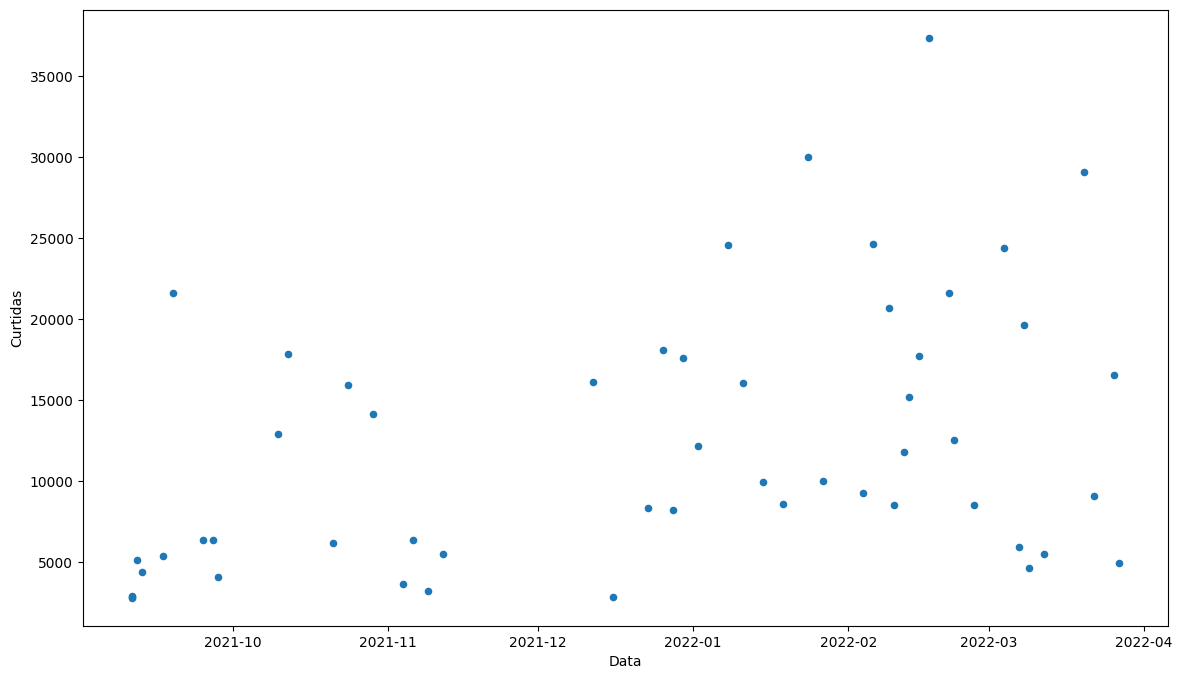

In [ ]:
# Um gráfico de disperção ajudaria a entender melhor curtidas e comentários
data.plot(kind= "scatter", x="Data", y="Curtidas", figsize=(14,8));

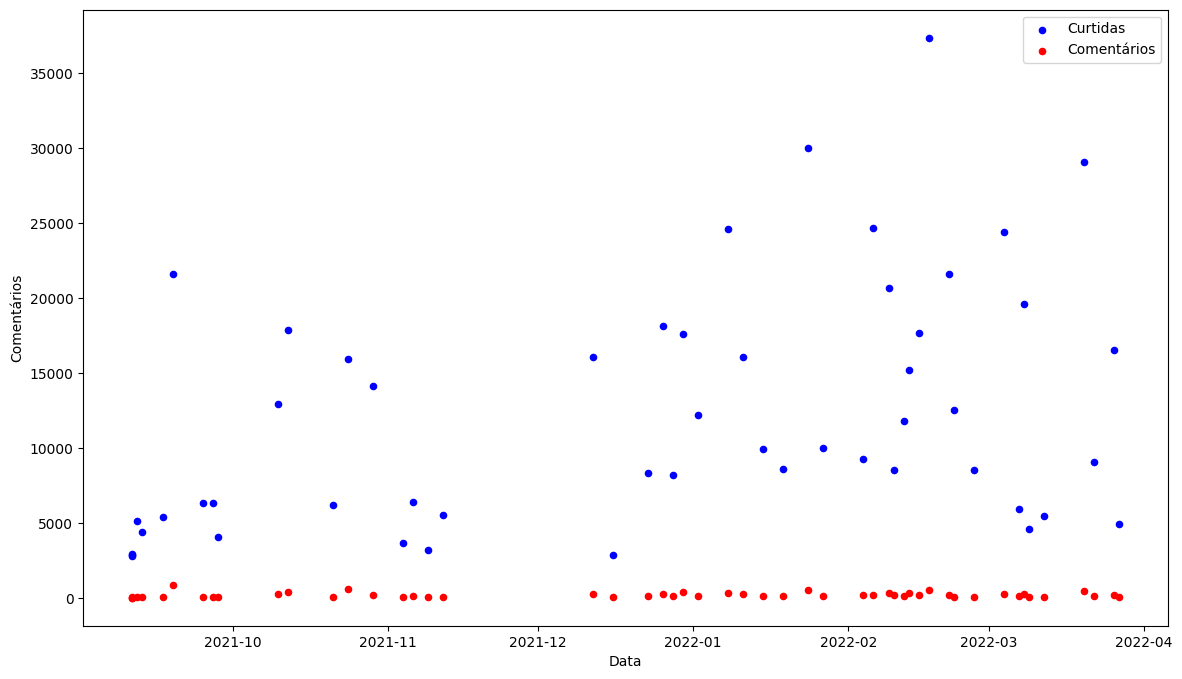

In [ ]:
# Podemos colocar curtidas e comentários no mesmo gráfico
ax = data.plot(kind="scatter", x="Data", y="Curtidas", color="blue", label="Curtidas", figsize=(14,8));
data.plot(kind="scatter", x="Data", y="Comentários", color="red", label="Comentários", figsize=(14,8), ax=ax);

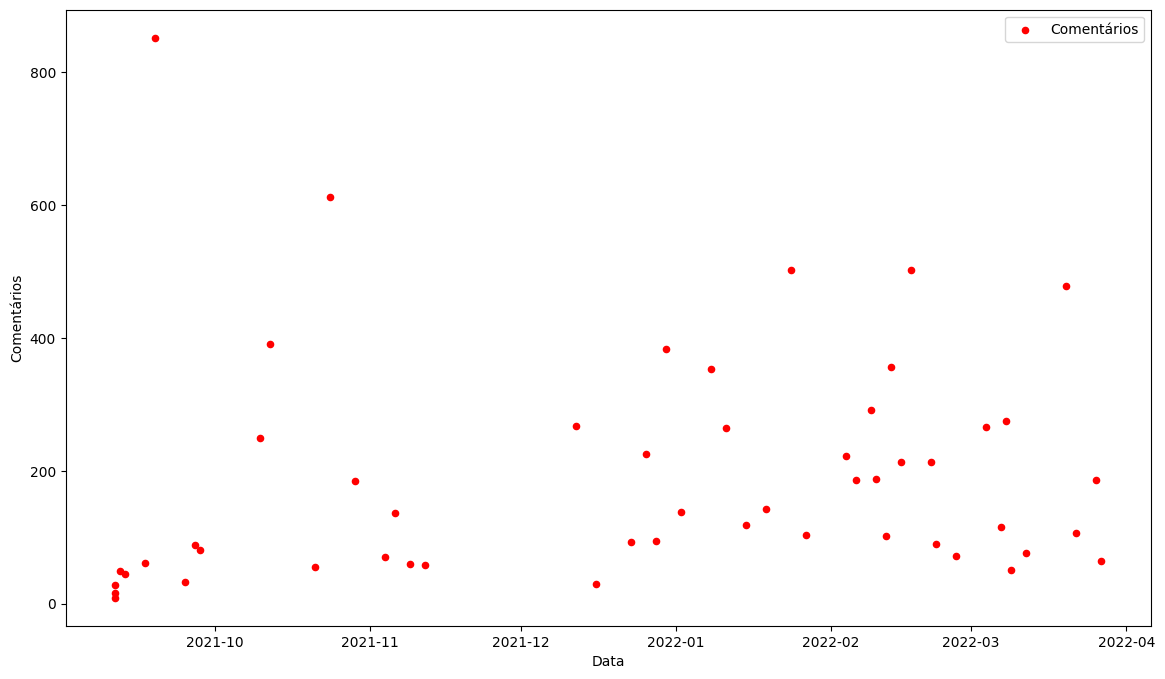

In [ ]:
data.plot(kind="scatter", x="Data", y="Comentários", color="red", label="Comentários", figsize=(14,8));



*   O gráfico e as informações estatísticas não estão dizendo muita coisa, pois existe uma grande disperção entre curtidas e comentários
*   Precisamos verificar se existe um padrão usando as outras colunas de informações



### A primeira coisa que podemos fazer é pegar os 5 primeiros registros com mais e menos curtidas

In [ ]:
# Ordenando os valores
data.sort_values(by= "Curtidas", ascending=False).head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
39,Foto,2022-02-17,37351,502,Promoções,S,S,N,37853
30,Reels,2022-01-24,29981,502,Trends,S,S,N,30483
48,Foto,2022-03-20,29084,479,Datas comemorativas/Promoções,S,S,N,29563
33,Foto,2022-02-06,24655,186,Influenciadores,S,S,N,24841
26,Foto,2022-01-08,24585,354,Datas comemorativas,S,S,S,24939


In [ ]:
# Ordenando os valores de forma ascendente
data.sort_values(by="Curtidas").head()

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
2,Foto,2021-09-11,2807,9,Loja,N,N,N,2816
0,Foto,2021-09-11,2858,16,Loja,N,N,N,2874
20,Foto,2021-12-16,2881,29,Produtos,N,N,N,2910
1,Foto,2021-09-11,2930,28,Loja/Produtos,N,N,N,2958
17,Vídeo,2021-11-09,3213,60,Produtos,N,N,N,3273




*   Podemos observar que no top 5 todas as postagens tinham pessoas e eram fotos de campanha
*   Nas 5 piores postagens, não haviam pessoas e nem eram postagens de campanhas

* **Isso pode ser um indicador que pessoas e campanhas tem relação com as curtidas**



### Vamos usar o group by para entender melhor os dados

In [ ]:
# Para melhorar a visualização, vamos criar um padrão no formato dos valores
pd.options.display.float_format = '{:,.2f}'.format

In [ ]:
# Agrupando as informações por tipo
data.groupby("Tipo")["Curtidas"].mean()

,Curtidas
Tipo,
Foto,"13,341.14"
IGTV,"6,833.40"
Reels,"14,873.00"
Vídeo,"8,141.50"


In [ ]:
# Agrupando por Tipo e Pessoas
data.groupby(["Tipo", "Pessoas"])["Curtidas"].mean()

Tipo   Pessoas
Foto   N          3,863.50
       S         15,236.67
IGTV   S          6,833.40
Reels  N          5,934.50
       S         20,832.00
Vídeo  N          4,007.50
       S         16,409.50
Name: Curtidas, dtype: float64

In [ ]:
data.groupby(["Tipo", "Pessoas"])[["Curtidas", "Comentários"]].mean()

Curtidas  Comentários
Tipo  Pessoas                       
Foto  N        3,863.50        29.50
      S       15,236.67       226.20
IGTV  S        6,833.40       133.60
Reels N        5,934.50        98.00
      S       20,832.00       342.00
Vídeo N        4,007.50        65.25
      S       16,409.50       370.00

In [ ]:
# Incluindo a coluna de campanhas
data.groupby(["Tipo", "Pessoas", "Campanhas"])[["Curtidas", "Comentários"]].mean()

Curtidas  Comentários
Tipo  Pessoas Campanhas                       
Foto  N       N          2,869.00        20.50
              S          5,852.50        47.50
      S       N         10,815.29       159.93
              S         19,105.38       284.19
IGTV  S       N          6,833.40       133.60
Reels N       N          5,934.50        98.00
      S       N         12,894.00       249.00
              S         24,801.00       388.50
Vídeo N       N          4,007.50        65.25
      S       S         16,409.50       370.00

In [ ]:
# Somente para pessoas
data.groupby("Pessoas")[["Curtidas", "Comentários"]].mean()

,Curtidas,Comentários
Pessoas,,
N,"4,256.67",52.83
S,"14,664.55",230.50


In [ ]:
# Somente para Campanhas
data.groupby("Campanhas")[["Curtidas", "Comentários"]].mean()

,Curtidas,Comentários
Campanhas,,
N,"7,928.33",123.17
S,"18,173.27",279.95


In [ ]:
# Podemos filtrar por Carrossel para entender o engajamento.
# Mas para isso, teremos que filtrar a base, para não colocarmos na conta o tipo Reels

data[data.Tipo == "Foto"].groupby("Carrossel")[["Curtidas", "Comentários"]].mean()

,Curtidas,Comentários
Carrossel,,
N,"13,776.36",208.57
S,"11,817.88",140.38


* **A média sem usar carrossel é melhor do que quando usamos, então não é algo que possa impactar tanto no resultado das mídias dessa empresa olhando inicialmente **
  * Nesse caso devemos filtrar apenas as fotos, pois só temos carrossel em fotos. Sem esse filtro estaríamos comparando coisas erradas

In [ ]:
# Agregando por Pessoas e Campanhas
data.groupby(["Pessoas", "Campanhas"])[["Curtidas", "Comentários"]].mean()

Curtidas  Comentários
Pessoas Campanhas                       
N       N          3,937.50        53.90
        S          5,852.50        47.50
S       N          9,923.75       157.80
        S         19,405.35       303.20

**A média quando tem pessoas E é publicação de campanhas é de cerca de 19,4 mil curtidas. Já quando é apenas pessoas (sem campanha) passa para quase 10 mil e se não tiver pessoas, chega no máximo a 5,9 mil mesmo em campanhas**


In [ ]:
# Agregando por pessoas, campanhas e tipo
data.groupby(["Pessoas", "Campanhas", "Tipo"])[["Curtidas", "Comentários"]].mean()

Curtidas  Comentários
Pessoas Campanhas Tipo                        
N       N         Foto   2,869.00        20.50
                  Reels  5,934.50        98.00
                  Vídeo  4,007.50        65.25
        S         Foto   5,852.50        47.50
S       N         Foto  10,815.29       159.93
                  IGTV   6,833.40       133.60
                  Reels 12,894.00       249.00
        S         Foto  19,105.38       284.19
                  Reels 24,801.00       388.50
                  Vídeo 16,409.50       370.00

* Analisando novamente a questão do vídeo, ele não parece mais tão ruim assim. Quando feito em campanha e usando pessoas ele teve um resultado bom, inclusive próximo a foto

* O que poderia ter levado a média baixa é que só temos vídeo ou COM pessoa e COM campanha, ou sem nenhum dos dois. Não temos nenhum vídeo com apenas um dos dois (pessoa ou campanha)

* Já IGTV, mesmo tendo pessoa, não teve um resultado tão bom

### Inclusive podemos entender o que havia gerado a média baixa no vídeo

In [ ]:
# Vamos filtrar a base apenas onde o tipo é Vídeo
data[data.Tipo == 'Vídeo']

,Tipo,Data,Curtidas,Comentários,Tags,Pessoas,Campanhas,Carrossel,Interacoes
3,Vídeo,2021-09-12,5115,49,Produtos,N,N,N,5164
9,Vídeo,2021-09-28,4056,81,Produtos,N,N,N,4137
15,Vídeo,2021-11-04,3646,71,Produtos,N,N,N,3717
17,Vídeo,2021-11-09,3213,60,Produtos,N,N,N,3273
24,Vídeo,2021-12-30,17600,383,Trends,S,S,N,17983
37,Vídeo,2022-02-13,15219,357,Datas comemorativas,S,S,N,15576


* Aqui percebemos que a loja tentou postar 4 videos mostrando seus produtos (Sem nenhuma pessoa) e o resultado foi baixo. Quando o video foi feito com pessoas aproveitando trends e datas comemorativas, o resultado foi bom!

### Conclusões

* Em uma análise inicial, postagens incluindo pessoas engajam muito mais que aquelas que não possui ninguém
* Postagens em épocas de campanhas também possuem um melhor engajamento
* Nessa base, o carrossel não foi um diferencial para melhorar o engajamento da marca